# Figure 1a
Cell population dynamics -/+ erlotinib on different stiffnesses

#### Load libraries
Should use ECM_model conda environment (see README)

In [8]:
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from pathlib import Path
import re

from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  
`DATADIR` = Path to data files  


In [9]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
DATADIR = "../../Data/Exp_Cell_Counts"

rcParams.update({'figure.autolayout': True})


In [10]:
filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.match(r'^DIP_DS8', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths.sort()
filepaths

[WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_0p2kPa_DMSO.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_0p2kPa_ERL.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_4kPa_DMSO.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_4kPa_ERL.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_55kPa_DMSO.txt'),
 WindowsPath('../../Data/Exp_Cell_Counts/DIP_DS8_55kPa_ERL.txt')]

In [11]:
all_response = []
for f in filepaths:
    all_response.append(np.loadtxt(f,delimiter=','))

means=[]
for vals in range(len(all_response)):
    means.append(np.mean(all_response[vals],axis=1))
    
stdevs=[]
for vals in range(len(all_response)):
    stdevs.append(np.std(all_response[vals],axis=1))
  
t = np.arange(0,420/3,1/3)
t1 = np.arange(0,363/3,1/3)


In [12]:
means

[array([ 0.       ,  0.0756301, -0.010578 ,  0.0183783,  0.1659935,
         0.0566422,  0.0026667, -0.0059043,  0.189882 ,  0.1681135,
         0.4673419,  0.1267439,  0.3099839,  0.311687 ,  0.1352164,
         0.0814402,  0.0983341,  0.257355 ,  0.3898727,  0.2158462,
         0.3764089,  0.1646493,  0.2216094,  0.420241 ,  0.2716092,
         0.3763519,  0.2469473,  0.698707 ,  0.540164 ,  0.592972 ,
         0.699887 ,  0.2377164,  0.288543 ,  0.693143 ,  0.2900897,
         0.539397 ,  0.434908 ,  0.7670429,  0.715985 ,  0.6045939,
         0.467774 ,  0.544807 ,  0.981796 ,  0.4043822,  0.708233 ,
         0.637678 ,  0.641742 ,  0.395192 ,  0.67977  ,  0.489896 ,
         1.49865  ,  0.793432 ,  0.463398 ,  0.785106 ,  0.608059 ,
         0.491333 ,  0.4191694,  0.520332 ,  0.495697 ,  0.598877 ,
         0.786903 ,  0.533358 ,  0.698437 ,  0.769077 ,  0.540445 ,
         0.535917 ,  0.88596  ,  0.854909 ,  0.608843 ,  0.610223 ,
         0.887877 ,  0.817992 ,  0.550641 ,  0.5

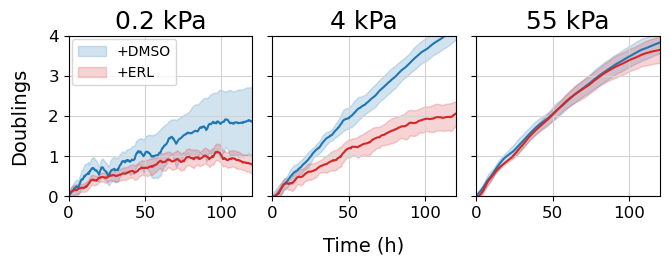

In [13]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

axes[0].plot(t, savgol_filter(means[0],win,pol), color=c1)
axes[0].fill_between(t, savgol_filter(means[0] - stdevs[0],win,pol),
                     savgol_filter(means[0] + stdevs[0],win,pol), color=c1, alpha=0.2, label='+DMSO')
axes[0].plot(t, savgol_filter(means[1],win,pol), color=c2)
axes[0].fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c2, alpha=0.2, label='+ERL')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('0.2 kPa')
axes[0].grid(color='lightgray')
axes[0].legend(loc=(0.02,0.69))

axes[1].plot(t, savgol_filter(means[2],win,pol), color=c1)
axes[1].fill_between(t, savgol_filter(means[2] - stdevs[2],win,pol), 
                     savgol_filter(means[2] + stdevs[2],win,pol), color=c1, alpha=0.2)
axes[1].plot(t, savgol_filter(means[3],win,pol), color=c2)
axes[1].fill_between(t, savgol_filter(means[3] - stdevs[3],win,pol), 
                     savgol_filter(means[3] + stdevs[3],win,pol), color=c2, alpha=0.2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].title.set_text('4 kPa')
axes[1].grid(color='lightgray')

axes[2].plot(t1, savgol_filter(means[4],win,pol), color=c1)
axes[2].fill_between(t1, savgol_filter(means[4] - stdevs[4],win,pol), 
                     savgol_filter(means[4] + stdevs[4],win,pol), color=c1, alpha=0.2)
axes[2].plot(t1, savgol_filter(means[5],win,pol), color=c2)
axes[2].fill_between(t1, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].title.set_text('55 kPa')
axes[2].grid(color='lightgray')


    
ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Doublings', labelpad=25)
fig.tight_layout(rect=(0, 0, 1, 1))

fig1a_fn = Path(SAVEDIR, 'fig1a.svg')

if SAVEFILES and (OVERWRITE or not fig1a_fn.exists()):
    plt.savefig(fig1a_fn, bbox_inches='tight')
else:
    plt.figure()

# Fig 1b
Distributions of intermitotic times (IMT) of cells treated with erlotinib (red shading) or DMSO control (blue shading) on three different substrate stiffnesses.

In [14]:
IMT_DATADIR = Path("../../Data/Exp_Intermitotic_Times")

In [15]:
file_location = os.path.join(IMT_DATADIR,'*imt_*.csv')
filenames = glob.glob(file_location)
filenames.sort()
filenames


['..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\02kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\06kpa_erl_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_dmso_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\4kpa_erl_imt_190118.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_dmso_imt_181017.csv',
 '..\\..\\Data\\Exp_Intermitotic_Times\\55kpa_erl_imt_181017.csv']

In [16]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 

### Define exponentially modified Gaussian (EMG) function

In [17]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponentially modified gaussian

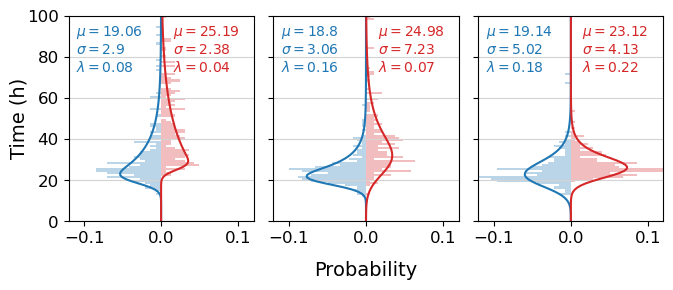

In [18]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

data = np.array(IMTs[0]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


data = np.array(IMTs[1]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[4]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[5]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[6]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[7]["IMT_t"])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))

fig1b_fn = Path(SAVEDIR, 'fig1b.svg')

if SAVEFILES and (OVERWRITE or not fig1b_fn.exists()):
    plt.savefig(fig1b_fn, bbox_inches='tight')
else:
    plt.figure()

# Fig 1c
IMT fits with convolution of two EMGs  
erlotinib-treated only for 3 ECM stiffnesses  


In [19]:
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity
import scipy.optimize as opt

### Define functions to calculate model fit comparison metrics
Bayesian information criterion (bic)and Aikaike's information criterion (aic)

In [20]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic


### Define other functions for fitting EMG and EMG convolution


In [21]:
from math import log10, floor
def round_sig(x, sig=2):
   return round(x, sig-int(floor(log10(abs(x))))-1)

def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-12
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

# def logl_emg2v2(log_par, data):
#     l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
#     eps = 10e-12
#     return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

def logl_emg2v2(log_par, data):
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-9
    temg2 = list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))
    emg2 = [x + eps for x in temg2]
    return np.log(emg2).sum()

def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp


def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params



In [22]:
init = [[-2.952, 0.369, 2.329, -2.253, 2.444, 3.315, -0.548], 
       [-2.145, 0.894, 2.314, -2.709, 1.079, 3.412, -0.105],
       [-0.452, 0.396, 2.388, -1.480, 1.021, 2.768, -0.010]]

In [23]:
def fit_EMGMM(dat=all_IMTs, cond=pd.Series(data={'stiff':0.2, 'drug':'ERL'}), 
              initial=init[0], ax=None, loc=4):
    G1_times = dat[(dat['Stiffness']==cond['stiff']) & (dat['Drug']==cond['drug'])]['G1_t']
    G1_times = G1_times[~np.isnan(G1_times)]
    
    params = exponnorm.fit(G1_times)
    exp_c = 1/(params[0]*params[2])
    LL = exponnorm.logpdf(G1_times,*params).sum()
    AIC = calculate_aic(LL, 3)
    AICc = calc_aicc(AIC, 3, len(G1_times))
    
    bounds = ((-5, 5),
             (-5, 8),
             (-5, 8),
             (-5, 5),
             (-5, 8),
             (-5, 8),
             (-10, -0.00000001))

    [log_p2, params2] = emg2_mle_v2(G1_times, initial, bounds)

    x = np.arange(0,100,0.1)
    y = emg_fit_func_2(x,*params2)
    y1 = emg_fit_func(x, params2[0], params2[1], params2[2])*params2[6]
    y2 = emg_fit_func(x, params2[3], params2[4], params2[5])*(1-params2[6])
    y3 = exponnorm.pdf(x, *params)
    ax.plot(x,y, color='black')
    ax.plot(x,y1, color='black', linestyle='dashed')
    ax.plot(x,y2, color='black', linestyle='dashed')
    ax.plot(x,y3, color='gray')
    h, edges =np.histogram(G1_times, bins=range(0,101), density=True)
    ax.stairs(h, edges, fill=True, color="tab:red", alpha=0.2)

    LL2 = logl_emg2v2(log_p2, G1_times)
    AIC2 = calculate_aic(LL2, 7)
    AICc2 = calc_aicc(AIC2, 7, len(G1_times))
    
    AICs = [AICc, AICc2]
    AICp = calc_aicp(AICs)
    AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3)]
    
    rc('text', usetex=True)
    ax.text(loc, 0.11, r'$\underline{AICp}$', fontsize=12)
    rc('text', usetex=False)
    ax.text(loc, 0.097, f'EMG: {AICp_r[0]}', fontsize=12, color='gray')
    ax.text(loc, 0.087, f'EMG2: {AICp_r[1]}', fontsize=12)

    out = pd.Series(data={'LL':LL, 'AIC':AIC, 'AICc':AICc, 'params':params,
                         'LL2':LL2, 'AIC2':AIC2, 'AICc2':AICc2, 'params2':params2, 'AICp':AICp_r})
          
    return(out)
    

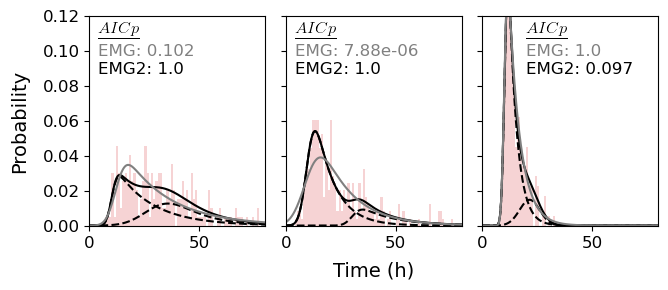

In [24]:
win = 21
pol = 2
size = (7.25,3.25)
ymin = 0
ymax = 0.12
xmin = 0
xmax = 80

# rc('text', usetex=True)
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

f0 = fit_EMGMM(cond=pd.Series(data={'stiff':0.2, 'drug':'ERL'}), initial=init[0], ax=axes[0])
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
f1 = fit_EMGMM(cond=pd.Series(data={'stiff':4, 'drug':'ERL'}), initial=init[1], ax=axes[1])
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
f2 = fit_EMGMM(cond=pd.Series(data={'stiff':55, 'drug':'ERL'}), initial=init[2], ax=axes[2], loc=20)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])

ax1 = fig.add_subplot(111, frameon=False)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlabel('Time (h)', labelpad=22)
ax1.set_ylabel('Probability', labelpad=40)
fig.tight_layout(rect=(0, 0, 1, 1))

fig1c_fn = Path(SAVEDIR, 'fig1c.svg')

if SAVEFILES and (OVERWRITE or not fig1c_fn.exists()):
    plt.savefig(fig1c_fn, bbox_inches='tight')
else:
    plt.figure()

In [25]:
f1.params2

[0.11715460067050863,
 2.770605144759112,
 9.909702283948937,
 0.06632580603856048,
 3.0384383884009543,
 30.543109596039212,
 0.7975288151070639]

In [26]:
log_par2 = [math.log(x) for x in f1.params2 ]

In [27]:
log_par2

[-2.1442608431775163,
 1.0190657601514572,
 2.2935143059076744,
 -2.713176226170355,
 1.1113436954092337,
 3.419139115040642,
 -0.22623731318018367]